In [8]:
import pandas as pd
df = pd.read_csv(r'C:\Users\vedik\OneDrive\Desktop\Data Analyst\ChatGpt Review Analysis.csv')
df.head()


,Unnamed: 0,userName,content,score,thumbsUpCount,at
0,0,T H (Trudylh20),excellent Im impressed 👌 👏,5,0,28-06-2024 21:07
1,1,Muhammad bassam adam,perfect,5,0,28-06-2024 20:56
2,2,Chinaza Okoli,its been so helpful...love it,5,0,28-06-2024 20:54
3,3,Project House Group Ltd,It's amazing tools help me a lot with my work.,5,0,28-06-2024 20:51
4,4,Safoan Riyad,I enjoyed ChatGPT. But last update ruined ever...,1,0,28-06-2024 20:50


In [9]:
df.columns = df.columns.str.strip().str.lower()
df['content'] = df['content'].fillna('')
df['at'] = pd.to_datetime(df['at'])
df.info()

C:\Users\vedik\AppData\Local\Temp\ipykernel_10688\975760166.py:3: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['at'] = pd.to_datetime(df['at'])


<class 'pandas.DataFrame'>
RangeIndex: 149719 entries, 0 to 149718
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   unnamed: 0     149719 non-null  int64         
 1   username       149719 non-null  str           
 2   content        149719 non-null  str           
 3   score          149719 non-null  int64         
 4   thumbsupcount  149719 non-null  int64         
 5   at             149719 non-null  datetime64[us]
dtypes: datetime64[us](1), int64(3), str(2)
memory usage: 6.9 MB


In [10]:
import subprocess
import sys

subprocess.check_call([sys.executable, "-m", "pip", "install", "textblob", "--break-system-packages"])

from textblob import TextBlob


def get_sentiment(text):
    blob = TextBlob(str(text))
    return blob.sentiment.polarity, blob.sentiment.subjectivity

df[['polarity', 'subjectivity']] = df['content'].apply(lambda x: pd.Series(get_sentiment(x)))


def categorize_sentiment(polarity):
    if polarity > 0:
        return 'Positive'
    elif polarity < 0:
        return 'Negative'
    else:
        return 'Neutral'

df['sentiment'] = df['polarity'].apply(categorize_sentiment)

df[['content', 'score', 'polarity', 'subjectivity', 'sentiment']].head()

,content,score,polarity,subjectivity,sentiment
0,excellent Im impressed 👌 👏,5,1.00,1.000000,Positive
1,perfect,5,1.00,1.000000,Positive
2,its been so helpful...love it,5,0.00,0.000000,Neutral
3,It's amazing tools help me a lot with my work.,5,0.60,0.900000,Positive
4,I enjoyed ChatGPT. But last update ruined ever...,1,0.25,0.383333,Positive


C:\Users\vedik\AppData\Local\Temp\ipykernel_10688\1183348864.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='sentiment', palette='Set2')


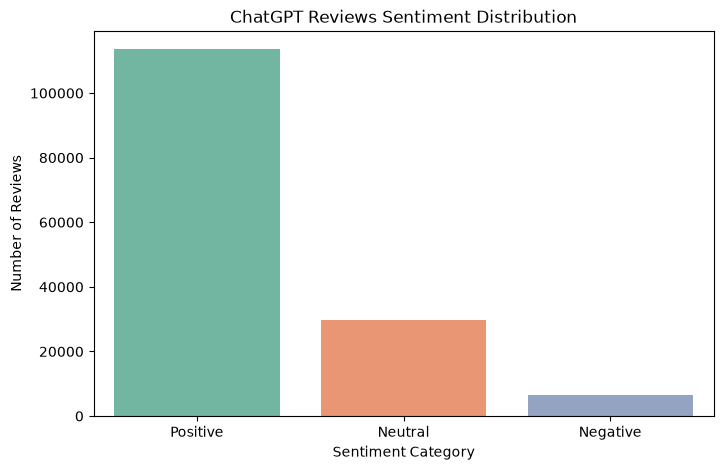

C:\Users\vedik\AppData\Local\Temp\ipykernel_10688\1183348864.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='score', y='polarity', palette='coolwarm')


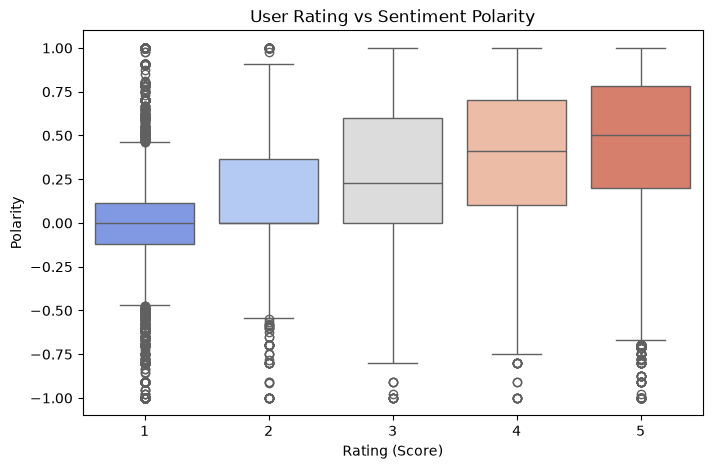

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='sentiment', palette='Set2')
plt.title('ChatGPT Reviews Sentiment Distribution')
plt.xlabel('Sentiment Category')
plt.ylabel('Number of Reviews')
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='score', y='polarity', palette='coolwarm')
plt.title('User Rating vs Sentiment Polarity')
plt.xlabel('Rating (Score)')
plt.ylabel('Polarity')
plt.show()

In [12]:
import sys
!{sys.executable} -m pip install matplotlib seaborn --break-system-packages

In [13]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


error: externally-managed-environment

× This environment is externally managed
╰─> This Python installation is managed by uv and should not be modified.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detailed specification.
